# Directed Acyclic Graphs (DAGs)

This notebook is a personal tutorial exploring DAGs for causal inference.

Goals:

- Learn how DAGs are represented in Python.
- Construct and visualise DAGs in Python.
- Understand confounders, mediators and colliders.
- Learn how DAGs guide statistical adjustment.
- Prepare for constructing the Bradford oral health DAG.

Packages:
- NetworkX
- Matplotlib

In [1]:
import sys
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

print(sys.executable)
print(nx.__version__)
print(matplotlib.__version__)


/home/amtjke/code/bradford-formula-oral-health/.venv/bin/python
3.6.1
3.11.0



## 1. What is a DAG?

A directed acyclic graph (DAG) is a graph in which

- every edge has a direction,
- there are no directed cycles,
- the arrows represent assumed causal relationships.

DAGs encode our assumptions about how variables influence one another and help determine which variables should be adjusted for in a causal analysis.


## 2. first DAG

Suppose we want to answer the question:

> Does exercise reduce blood pressure?

We believe that age influences both how much people exercise and their blood pressure. We also believe that exercise influences body weight, which in turn affects blood pressure.

These assumptions can be represented as a directed acyclic graph.

In [2]:
dag = nx.DiGraph()

print(dag)

DiGraph with 0 nodes and 0 edges


In [3]:
dag.add_nodes_from([
    "Age",
    "Exercise",
    "Body weight",
    "Blood pressure"
])

print(dag.nodes)

['Age', 'Exercise', 'Body weight', 'Blood pressure']


The graph currently contains variables only.
No causal assumptions have yet been encoded.

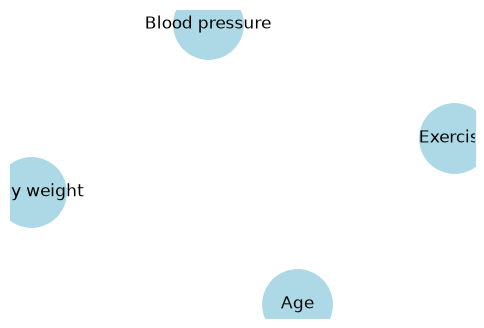

In [4]:
plt.figure(figsize=(6,4))

nx.draw_networkx(
    dag,
    node_color="lightblue",
    node_size=2500
)

plt.axis("off")
plt.show()

In [5]:
# add the info that changing exercise changes blood pressure
dag.add_edge(
    "Exercise",
    "Blood pressure"
)

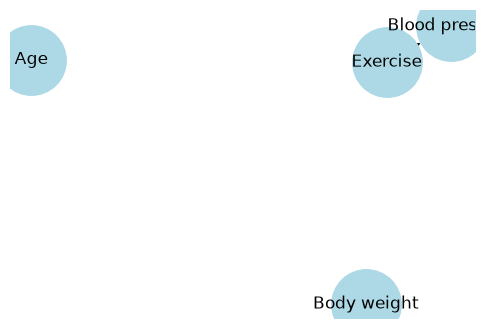

In [6]:
# 
plt.figure(figsize=(6,4))

nx.draw_networkx(
    dag,
    node_color="lightblue",
    node_size=2500,
    arrows=True,
    arrowsize=20
)

plt.axis("off")
plt.show()

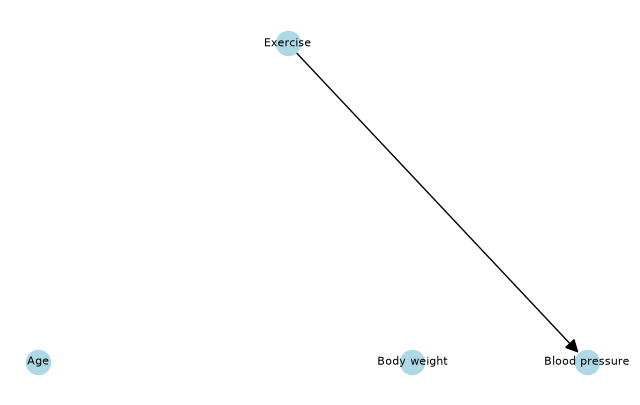

In [7]:
# force the node positions 
positions = {
    "Age": (0, 1),
    "Exercise": (1, 2),
    "Body weight": (1.5, 1),
    "Blood pressure": (2.2, 1),
}

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=positions,
    node_color="lightblue",
    node_size=300,
    font_size=8,
    arrowsize=20
)

plt.axis("off")
plt.show()

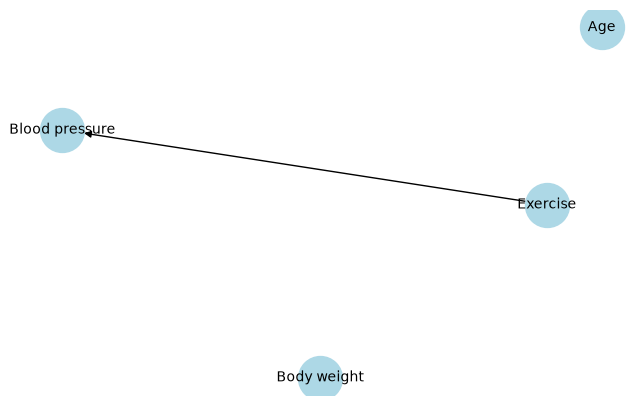

In [8]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()

### Notes

- A DAG represents assumptions, not observations.
- The arrows come from scientific knowledge.
- Data estimate the strength of relationships, not their existence.
- The same data can be explained by multiple DAGs.

## 3. Building the causal model

Each arrow represents a scientific assumption about how one variable influences another. We therefore add the arrows one at a time, justifying each before writing the code.

Each arrow should therefore answer the question:

> "If I could intervene and change this variable, would I expect it to
> causally influence the other?"

We now build the graph one relationship at a time.

In [9]:
# Add: age causally influences exercise
dag.add_edge("Age", "Exercise")

### Why add Age → Exercise?

This arrow represents the assumption that ageing influences physical
activity through physiological and lifestyle changes.

It does **not** mean that every older individual exercises less than
every younger individual.

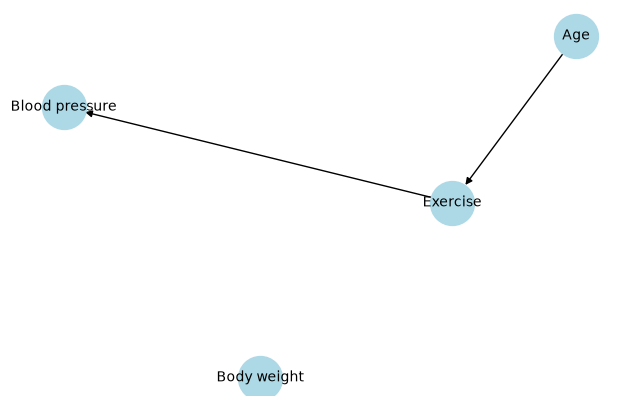

In [10]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()

In [11]:
# Add: age causally influences blood pressure
dag.add_edge("Age", "Blood pressure")

### Why add Age → Blood pressure?

Assumption: ageing influences blood pressure through arterial hardening, lifestyle and general health

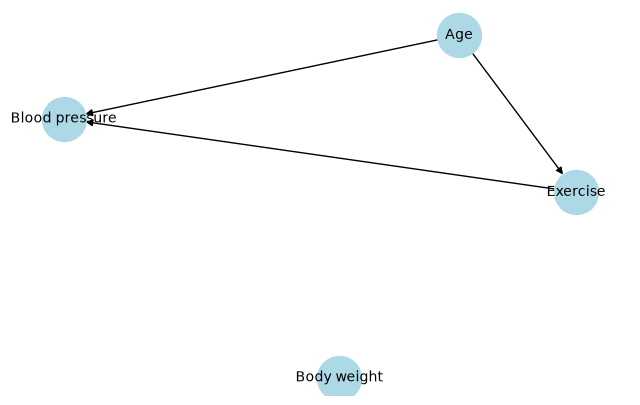

In [12]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()

### Confounding

If we ignore age and just look at people who exercise more or less, we will miss info because some of the apparent relationship between exercise and blood pressure is actually due to differences in age rather than exercise itself.

NB Acyclic: means you must never be able to follow the arrows back to where you began. So we can't have exercise - body weight - exercise (even though they may well be a feedback loop). This is one of the limitations of a DAG

So we need to ask, what is the question we're trying to answer?

If the question is: "What is the effect of exercise on blood pressure?" we think of exercise as the exposure and body weight as something it might alter. so we need exercise → bodyweight.

In [13]:
# Add: exercise causally influences body weight
dag.add_edge("Exercise", "Body weight")

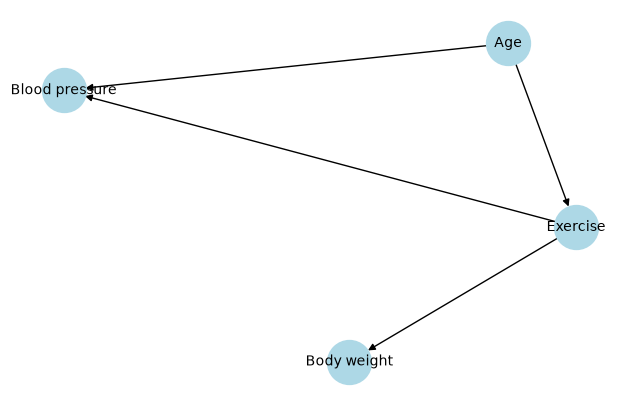

In [14]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()

### add age (arrow) body weight

Because of age-related changes in metabolism, muscle mass and body composition.

In [15]:
# Add: age causally influences body weight
dag.add_edge("Age", "Body weight")

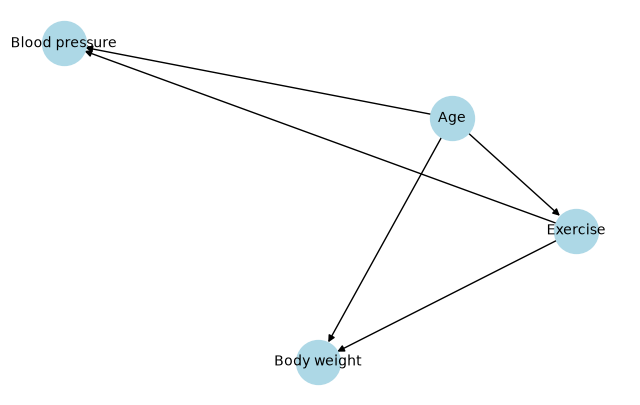

In [16]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()



### Why add Body weight → Blood pressure?

This arrow represents the assumption that changing body weight can influence
blood pressure. Body weight therefore lies on one possible causal pathway from
exercise to blood pressure.

In [17]:
dag.add_edge("Body weight", "Blood pressure")

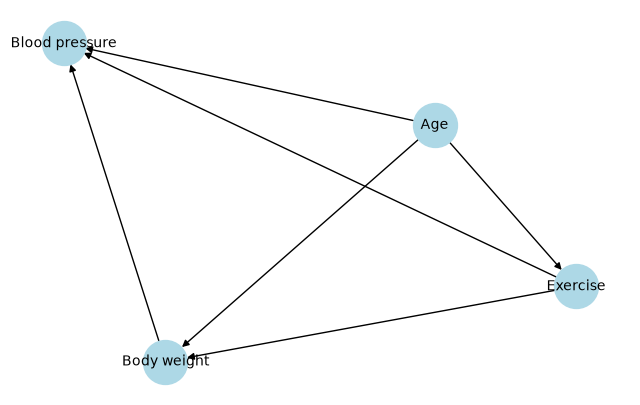

In [18]:
pos = nx.spring_layout(dag, seed=42, k=2)

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=pos,
    node_color="lightblue",
    node_size=1000,
    font_size=10
)

plt.axis("off")
plt.show()

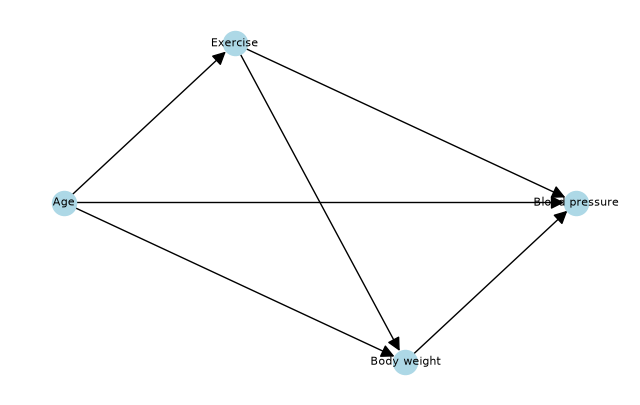

In [19]:
### with positions

# force the node positions 

positions = {
    "Age": (0, 1),
    "Exercise": (1, 1.5),
    "Body weight": (2, 0.5),
    "Blood pressure": (3, 1),
}

plt.figure(figsize=(8,5))

nx.draw_networkx(
    dag,
    pos=positions,
    node_color="lightblue",
    node_size=300,
    font_size=8,
    arrowsize=20
)

plt.axis("off")
plt.show()

Body weight acts as a mediator: exercise may affect blood pressure partly by changing body weight

In [20]:
print(nx.is_directed_acyclic_graph(dag))

True


In [21]:
paths = list(
    nx.all_simple_paths(
        dag,
        source="Exercise",
        target="Blood pressure",
    )
)

for path in paths:
    print(" → ".join(path))

Exercise → Blood pressure
Exercise → Body weight → Blood pressure


### Role of the DAG graph

If these are my assumptions about how the world works, what statistical analysis follows?

For example: Q: What is the total effect of exercise on blood pressure?

Should we adjust for age? the DAG says yes: Age influences both exercise and blood pressure, so failing to account for it could mix up the effect of exercise with the effect of age.

Should we adjust for body weight? Probably not if we're interested in the total effect of exercise, because exercise affects blood pressure VIA body weight. If we adjust for body weight, we're removing that path from the analysis. DAG says DON'T include that variable.

### For the real project:

Suppose the DAG eventually contains variables like

- Low-allergy formula prescription (exposure)
- Dental general anaesthetic (outcome)
- Socioeconomic status
- Prematurity
- Feeding difficulties
- Cow's milk allergy
- Sugar intake
- Tooth brushing
etc.

Once the DAG is agreed upon, it can answer questions such as:

- Which variables should be adjusted for?
- Which variables should not be adjusted for?
- Which variables are potential confounders?
- Which variables lie on the causal pathway?
- Which variables, if adjusted for, might introduce bias?



# Tests

## Verify that it's a DAG

In [23]:
nx.is_directed_acyclic_graph(dag)

True

## Questions

In [24]:
# what variables directlky influence blood pressure?
list(dag.predecessors("Blood pressure"))

['Exercise', 'Age', 'Body weight']

In [25]:
# what does age directly influence?
list(dag.successors("Age"))

['Exercise', 'Blood pressure', 'Body weight']

In [26]:
# Find all causal paths: what are all the paths from exercise to blood pressure?
paths = list(
    nx.all_simple_paths(
        dag,
        source="Exercise",
        target="Blood pressure"
    )
)

for path in paths:
    print(" → ".join(path))

Exercise → Blood pressure
Exercise → Body weight → Blood pressure


In [27]:
# age to blood pressure
paths = list(
    nx.all_simple_paths(
        dag,
        source="Age",
        target="Blood pressure"
    )
)

for path in paths:
    print(" → ".join(path))

Age → Exercise → Blood pressure
Age → Exercise → Body weight → Blood pressure
Age → Blood pressure
Age → Body weight → Blood pressure


Conc: Age can influence blood pressure in four different ways in our model

In [28]:
# body weight to exercise
paths = list(
    nx.all_simple_paths(
        dag,
        source="Body weight",
        target="Exercise"
    )
)

print(paths)

[]


In [29]:
# I want to estimate the total effect of exercise on blood pressure. Which variables should I adjust for?

adjustment_set = {"Age"}

 

## 4. Choosing an adjustment set

Research question:

> What is the total effect of exercise on blood pressure?

Age should be adjusted for because it is a common cause of both exercise and
blood pressure.

Body weight should not be adjusted for because it lies on a causal pathway from
exercise to blood pressure. Adjusting for it would remove part of the total
effect.

Therefore, the adjustment set is:

**Age**

In [30]:
# what happens if we adjust for body weight? (deliberate mistake!)

total_effect_adjustment = {"Age"}
direct_effect_adjustment = {"Age", "Body weight"}

print("Total effect:", total_effect_adjustment)
print("Direct effect:", direct_effect_adjustment)


Total effect: {'Age'}
Direct effect: {'Age', 'Body weight'}


## 5. What happens if we adjust for body weight?

Body weight is a mediator on the pathway

**Exercise → Body weight → Blood pressure**

If body weight is included as an adjustment variable, this pathway is blocked.
The resulting estimate therefore excludes the part of the effect of exercise
that operates through body weight.

Adjusting for age and body weight would estimate something closer to the
direct effect of exercise on blood pressure, rather than the total effect.

Including every available variable in a statistical
model is not necessarily appropriate: the adjustment set must match the
causal question.

## 6. Adding a collider

Exercise → Health programme participation ← High blood pressure

People may join a health programme because they exercise, or because they have high blood pressure. That makes Health programme participation a **collider** because two arrows point into it.

Do not adjust for it when estimating the effect of exercise on blood pressure. Conditioning on a collider can create a false association between its causes.

In [31]:
dag.add_node("Health programme")

dag.add_edges_from([
    ("Exercise", "Health programme"),
    ("Blood pressure", "Health programme"),
])

In [32]:
# move it below the main graph
positions["Health programme"] = (2, -0.5)

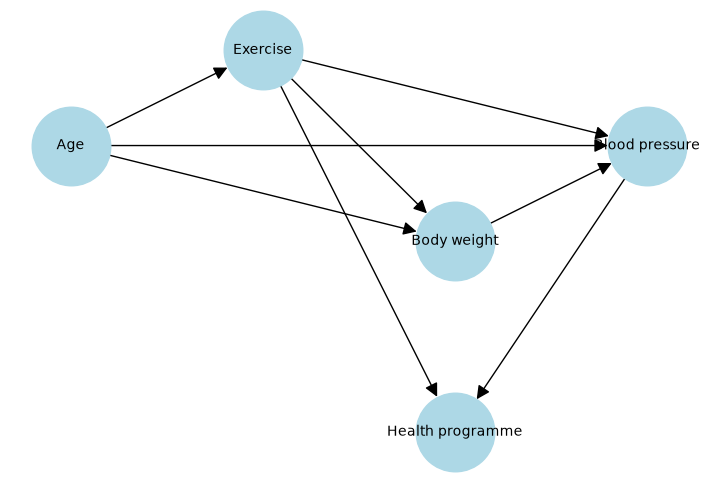

In [33]:
plt.figure(figsize=(9, 6))

nx.draw_networkx(
    dag,
    pos=positions,
    node_color="lightblue",
    node_size=3200,
    font_size=10,
    arrows=True,
    arrowsize=20,
)

plt.axis("off")
plt.show()

### Why is this a collider?

Health programme participation is caused by both exercise and blood pressure:

**Exercise → Health programme ← Blood pressure**

The arrows meet at the health programme node, so it is a collider.

If we condition on, adjust for, or restrict the analysis according to health
programme participation, we may create an association between exercise and
blood pressure that was not present before.

Therefore, health programme participation should not be included in the
adjustment set when estimating the total effect of exercise on blood pressure.

Confounder: Exercise ← Age → Blood pressure
Collider:   Exercise → Programme ← Blood pressure

**For a confounder, we adjust. For a collider, we usually don't**

## 7. Summary

This toy DAG illustrates three important types of variable.

### Confounder

**Exercise ← Age → Blood pressure**

Age is a common cause of exercise and blood pressure. It should be adjusted for
when estimating the total effect of exercise on blood pressure.

### Mediator

**Exercise → Body weight → Blood pressure**

Body weight lies on a causal pathway from exercise to blood pressure. It should
not be adjusted for when estimating the total effect, because doing so would
block part of that effect.

### Collider

**Exercise → Health programme ← Blood pressure**

Health programme participation is caused by both exercise and blood pressure.
Adjusting for it may introduce bias by creating an artificial association
between its causes.

### Adjustment set for the total effect

For this toy model, the appropriate minimal adjustment set is:

**Age**

Body weight and health programme participation should not be included.

In [34]:
print(nx.is_directed_acyclic_graph(dag))

True
